# 04 · Siting new rapid hubs under budget, capacity, grid and demand uncertainty

**Question.** With a given budget, where should the next 4 × 150 kW hubs go so that the most currently unmet or queue-constrained rapid demand is served within 8 minutes' drive — and which choices stay good if demand is lower or higher than expected, or the behavioural assumptions are wrong?

**Method.** Candidates = plausible hexes (parking / fuel / retail present or heavy traffic, primary substation not RED), pre-filtered to the 500 with most local unmet demand. Capacitated maximal covering MILP (HiGHS via SciPy) with per-hub capacity from Erlang C (P(wait) ≤ 15 % at the peak hour) and a budget; the MIP gap of every solve is recorded. Demand uncertainty: a plan is optimised for each scenario (P10, P50, P90) and every plan is evaluated *exactly* under every scenario (fixed-plan assignment LP), which gives expected coverage, regret, and a **robust core** — hubs chosen, in the same or an adjacent hex, whatever the demand level. Greedy uncapacitated coverage is shown for contrast.

*A note on the single two-stage robust MILP.* `facility.robust_capacitated_mclp` solves one plan against all three scenarios at once and passes its unit tests, but on the London instance HiGHS leaves a very large gap after 5 minutes — its incumbent is not a usable plan. Reporting it would be misleading, so the pipeline uses the exact scenario analysis above.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from chargescape.utils.paths import PROCESSED, INTERIM, FIGURES, TABLES, DOCS
from chargescape.utils.io import read_gdf
from chargescape.viz.figures import hex_map, save, barh, boroughs
from chargescape.utils.reference import dft_la, charging_sites
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
feats = read_gdf(PROCESSED / "hex_features_r8.small.parquet")
print(feats.shape)

(2374, 81)


In [2]:
meta = json.loads((TABLES / "siting_meta_2026.json").read_text()); print(meta)
sweep = pd.read_csv(TABLES / "siting_budget_sweep_2026.csv")
cap = meta["hub_capacity_sessions_day"]
sweep["capacity_bound_share"] = sweep["covered_p50"] / (sweep["n_hubs"] * cap)  # 1.0 = every hub is full
sweep["hubs_needed_for_all_unmet"] = np.ceil(sweep["total_unmet_p50"] / cap).astype(int)
sweep[["budget_m", "n_hubs", "covered_p50", "total_unmet_p50", "coverage_share", "mip_gap", "greedy_uncapacitated_covered", "capacity_bound_share", "hubs_needed_for_all_unmet"]].round(3)

{'method': 'osm_igraph', 'scenario': '2026', 'n_candidates': 500, 'hub_capacity_sessions_day': 33.31170119357964, 'radius_min': 8.0, 'hub_cost_gbp': 390000}


,budget_m,n_hubs,covered_p50,total_unmet_p50,coverage_share,mip_gap,greedy_uncapacitated_covered,capacity_bound_share,hubs_needed_for_all_unmet
0,5.0,12,399.740,2685.818,0.149,0.000,1883.693,1.000,81
1,10.0,25,832.793,2685.818,0.310,0.000,2248.145,1.000,81
2,20.0,51,1698.897,2685.818,0.633,0.000,2319.168,1.000,81
3,40.0,98,2307.789,2685.818,0.859,0.002,2319.168,0.707,81


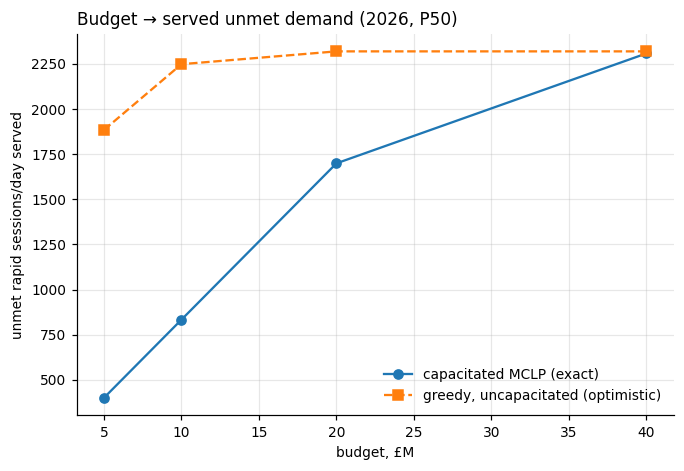

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sweep.budget_m, sweep.covered_p50, "o-", label="capacitated MCLP (exact)")
ax.plot(sweep.budget_m, sweep.greedy_uncapacitated_covered, "s--", label="greedy, uncapacitated (optimistic)")
ax.set_xlabel("budget, £M"); ax.set_ylabel("unmet rapid sessions/day served"); ax.set_title("Budget → served unmet demand (2026, P50)", loc="left"); ax.legend(frameon=False); ax.grid(alpha=0.3)
save(fig, "04_budget_curve.png"); plt.show()

## Demand uncertainty: every plan evaluated under every scenario

In [4]:
cross = pd.read_csv(TABLES / "siting_scenarios_2026.csv")
c20 = cross[cross.budget_m == 20]
share = c20.pivot(index="plan", columns="scenario", values="share").loc[["p10", "p50", "p90"], ["p10", "p50", "p90"]]
regret = c20.pivot(index="plan", columns="scenario", values="regret").loc[["p10", "p50", "p90"], ["p10", "p50", "p90"]]
print("Share of unmet demand served at £20M — rows: plan optimised for, columns: demand that materialises")
print((share * 100).round(1).to_string())
print("\nRegret (sessions/day lost vs the plan optimised for that scenario):")
print(regret.round(0).to_string())
sweep[["budget_m", "p50_plan_share_if_p10", "p50_plan_share_if_p90", "p50_plan_max_regret", "best_plan_by_expected", "best_plan_by_minimax_regret", "core_same_hex", "core_same_or_adjacent", "n_hubs"]].round(3)

Share of unmet demand served at £20M — rows: plan optimised for, columns: demand that materialises
scenario   p10   p50   p90
plan                      
p10       82.9  63.3  50.2
p50       76.0  63.3  50.2
p90       73.3  61.8  50.2

Regret (sessions/day lost vs the plan optimised for that scenario):
scenario    p10   p50  p90
plan                      
p10         0.0   0.0  0.0
p50       141.0   0.0  0.0
p90       197.0  39.0  0.0


,budget_m,p50_plan_share_if_p10,p50_plan_share_if_p90,p50_plan_max_regret,best_plan_by_expected,best_plan_by_minimax_regret,core_same_hex,core_same_or_adjacent,n_hubs
0,5.0,0.192,0.118,5.827,p10,p10,3,6,12
1,10.0,0.368,0.246,79.003,p10,p10,6,12,25
2,20.0,0.760,0.502,141.272,p10,p10,10,22,51
3,40.0,0.863,0.853,1.760,p90,p90,50,81,98


## The recommended £20M plan and its robust core

£20M recommended plan (optimised for P10 demand, smallest maximum regret): 51 hubs; robust core (same or adjacent hex in the other two scenario plans): 22; exactly the same hex: 10


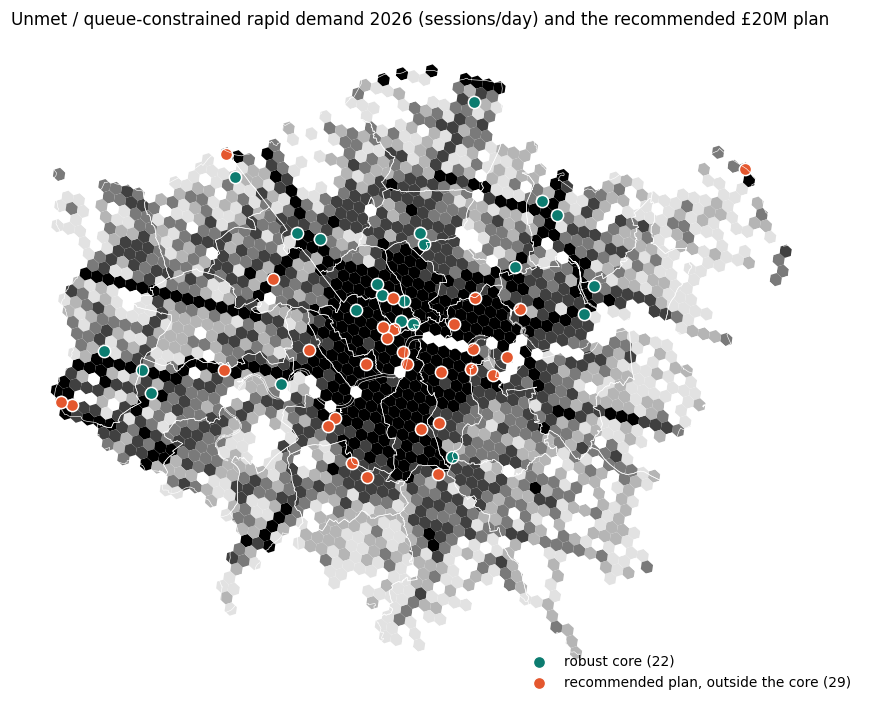

,hubs,core
borough,,
Camden,6,5
Westminster,5,1
Southwark,4,1
Hounslow,4,3
Hillingdon,3,1
Tower Hamlets,3,0
Lambeth,2,0
Redbridge,2,2
Wandsworth,2,0


In [5]:
sel = pd.read_parquet(PROCESSED / "siting_selected_2026.small.parquet")
rec = sweep.set_index("budget_m").loc[20, "best_plan_by_minimax_regret"]
s20 = sel[(sel.budget_m == 20) & (sel.model == rec)]
print(f"£20M recommended plan (optimised for {rec.upper()} demand, smallest maximum regret): {len(s20)} hubs; robust core (same or adjacent hex in the other two scenario plans): {int(s20.core.sum())}; exactly the same hex: {int(s20.core_exact.sum())}")
svc = pd.read_parquet(PROCESSED / "hex_service_2026.small.parquet")
g = feats.merge(svc, on="h3", how="left")
g["unmet"] = g["unserved_sessions_day"].fillna(0) + g["rapid_sessions_day"].fillna(0) * g["served_share"].fillna(0) * np.clip(g["expected_wait_min"].fillna(0) / 30, 0, 1)
fig, ax = plt.subplots(figsize=(10, 8))
hex_map(g, "unmet", "Unmet / queue-constrained rapid demand 2026 (sessions/day) and the recommended £20M plan", cmap="Greys", scheme="quantiles", k=6, ax=ax, legend_label="sessions/day")
hexes = feats.set_index("h3")
for flag, color, label in [(True, "#0c7c70", "robust core"), (False, "#e4572e", "recommended plan, outside the core")]:
    pts = hexes.loc[s20[s20.core == flag].h3]
    gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts.lon, pts.lat), crs=4326).to_crs(27700).plot(ax=ax, color=color, markersize=64, label=f"{label} ({len(pts)})", edgecolor="white")
ax.legend(loc="lower right", frameon=False); save(fig, "04_selected_hubs.png"); plt.show()
s20.groupby("borough").agg(hubs=("h3", "size"), core=("core", "sum")).sort_values("hubs", ascending=False).head(12)

## Sensitivity to behavioural and service assumptions (£20M)

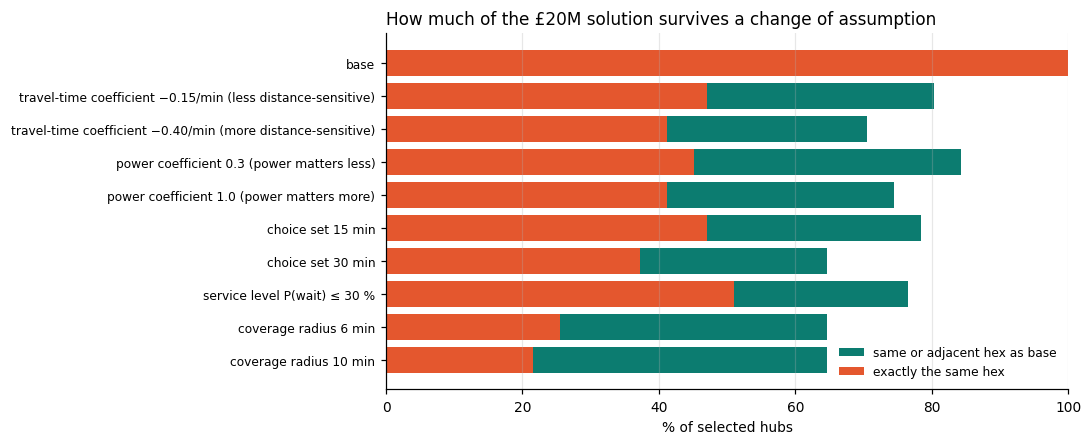

,variant,unmet_sessions_day,hub_capacity_sessions_day,n_hubs,coverage_share,mip_gap,same_hex_as_base,same_or_adjacent_hex
0,base,2685.818,33.312,51,0.633,0.000,1.000,1.000
1,travel-time coefficient −0.15/min (less distan...,2677.968,33.312,51,0.634,0.000,0.471,0.804
2,travel-time coefficient −0.40/min (more distan...,2959.553,33.312,51,0.574,0.000,0.412,0.706
3,power coefficient 0.3 (power matters less),2494.666,33.312,51,0.681,0.000,0.451,0.843
4,power coefficient 1.0 (power matters more),2972.194,33.312,51,0.572,0.000,0.412,0.745
5,choice set 15 min,2502.305,33.312,51,0.679,0.000,0.471,0.784
6,choice set 30 min,2740.651,33.312,51,0.620,0.000,0.373,0.647
7,service level P(wait) ≤ 30 %,2685.818,42.809,51,0.813,0.005,0.510,0.765
8,coverage radius 6 min,2685.818,33.312,51,0.630,0.009,0.255,0.647
9,coverage radius 10 min,2685.818,33.312,51,0.633,0.000,0.216,0.647


In [6]:
sens = pd.read_csv(TABLES / "sensitivity_2026_budget20m.csv")
show = sens[["variant", "unmet_sessions_day", "hub_capacity_sessions_day", "n_hubs", "coverage_share", "mip_gap", "same_hex_as_base", "same_or_adjacent_hex"]].copy()
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(show))[::-1]
ax.barh(y, show.same_or_adjacent_hex * 100, color="#0c7c70", label="same or adjacent hex as base")
ax.barh(y, show.same_hex_as_base * 100, color="#e4572e", label="exactly the same hex")
ax.set_yticks(y); ax.set_yticklabels(show.variant, fontsize=8); ax.set_xlim(0, 100); ax.set_xlabel("% of selected hubs")
ax.set_title("How much of the £20M solution survives a change of assumption", loc="left"); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)
save(fig, "04_sensitivity.png"); plt.show()
show.round(3)

## Reading
* **The regime is capacity-bound, not location-bound.** With a 15 % peak-wait service level a 4 × 150 kW hub absorbs about 33 sessions/day, so covered demand rises almost linearly with budget (`capacity_bound_share` ≈ 1) until roughly the number of hubs needed to absorb today's unmet demand (`hubs_needed_for_all_unmet`). The exact model serves a fraction of what the greedy uncapacitated estimate claims — that gap is demand a hub physically cannot take at an acceptable wait, which naïve coverage models hand out for free.
* **Plan for pessimistic demand while capacity binds.** Up to £20M the plan optimised for P10 demand has zero regret in every scenario (`best_plan_by_minimax_regret`): capacity-bound hubs placed where even low demand is dense fill up whatever happens, whereas hubs placed for median demand may not. At £40M, when capacity no longer binds everywhere, the recommendation flips to the P90 plan. The three scenario plans share a robust core (same or adjacent hex) that grows with budget; build the core first and phase the rest as utilisation data arrive.
* **Behavioural assumptions move the unmet total; the service standard moves coverage most.** Exact hexes reshuffle between variants — partly because the demand pattern shifts, partly because many near-equivalent hub sets exist when every hub is full — so "same or adjacent hex" is the more meaningful stability measure (table above). The corridors are robust, the exact hex is a local-survey decision.
* Every selected hex carries its primary-substation headroom label: a RED site never enters the candidate set and loaded primaries pay a connection uplift.